In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# KNN 머신러닝 모델
# KNN(K-Nearest Neighbors) -> K-최근접 이웃
#   => "미리 분류된" 기존/학습 데이터에 있어, K개의 가장 가까운 이웃들의 값으로 군집 예측
from sklearn.neighbors import KNeighborsClassifier

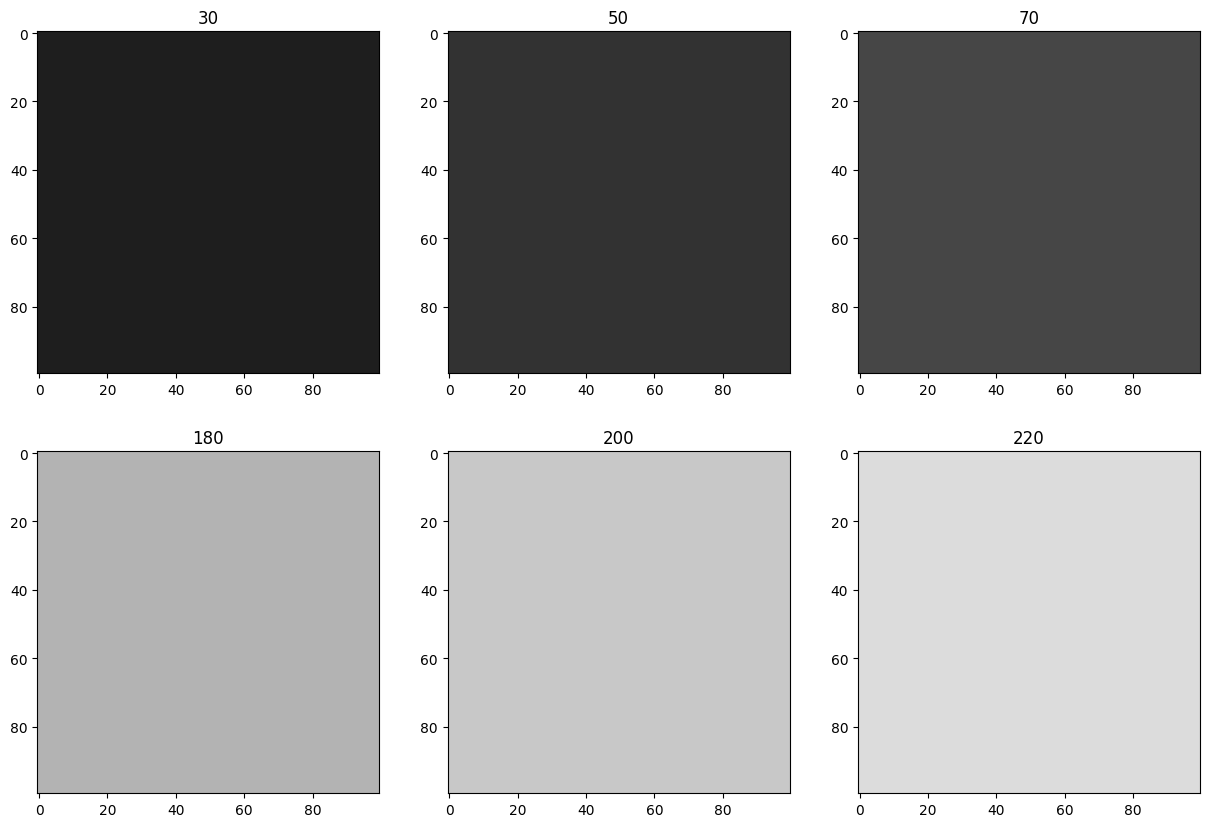

In [ ]:
# 1. 학습용 색상 임의 생성

# 어두운 이미지 3개
dark1 = np.full((100, 100), 30)     # 30 정도의 밝기 색상
dark2 = np.full((100, 100), 50)
dark3 = np.full((100, 100), 70)
# 밝은 이미지 3개
bright1 = np.full((100, 100), 180)
bright2 = np.full((100, 100), 200)
bright3 = np.full((100, 100), 220)

# 색상 확인
plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1)
plt.imshow(dark1, cmap='gray', vmin=0, vmax=255)
plt.title('30')
plt.subplot(2, 3, 2)
plt.imshow(dark2, cmap='gray', vmin=0, vmax=255)
plt.title('50')
plt.subplot(2, 3, 3)
plt.imshow(dark3, cmap='gray', vmin=0, vmax=255)
plt.title('70')
plt.subplot(2, 3, 4)
plt.imshow(bright1, cmap='gray', vmin=0, vmax=255)
plt.title('180')
plt.subplot(2, 3, 5)
plt.imshow(bright2, cmap='gray', vmin=0, vmax=255)
plt.title('200')
plt.subplot(2, 3, 6)
plt.imshow(bright3, cmap='gray', vmin=0, vmax=255)
plt.title('220')
plt.show()

In [ ]:
# 학습 데이터 준비 (군집화)
#   "X 배열값들은 각각 Y의 배열값들의 군집에 속한다" 라는 뜻으로  =>  fit(X, Y)

x = np.array([
    [np.mean(dark1)],
    [np.mean(dark2)],
    [np.mean(dark3)],
    [np.mean(bright1)],
    [np.mean(bright2)],
    [np.mean(bright3)],
])
# [가정] 0을 어두운 색상, 1을 밝은 색상   -> 2개의 군집
y = np.array([0, 0, 0, 1, 1, 1])

# dark1, dark2, dark3       => "어두운 색상" 군집으로 묶음
# bright1, bright2, bright3 => "밝은 색상" 군집으로 묶음

In [ ]:
# 머신러닝 모델 생성 + 학습
model = KNeighborsClassifier(n_neighbors = 3)      # KNN 모델 생성
#   (ex) 120 값이 어두운지 밝은지 테스트,
#     120과 가까운 3개의 학습 데이터(70, 180, 50) 참고하여 비교
#       (n_neighbors의 값을 총 군집의 개수에 따라 결정 (홀수 -> 짝수, 짝수 -> 홀수))

model.fit(x, y)   # (데이터들, 그 데이터들의 군집 분류)

KNeighborsClassifier(n_neighbors=3)

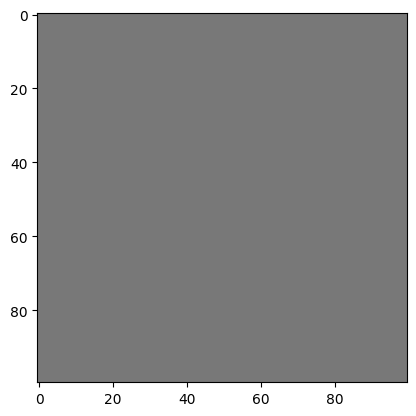

[0] 어두운 색상입니다.


In [ ]:
# KNN 모델 기반 예측 진행
test_img = np.full((100, 100), 120)
plt.imshow(test_img, cmap='gray', vmin=0, vmax=255)
plt.show()

avg = np.mean(test_img)       # avg = 120
result = model.predict([[avg]])   # 어두우면 result=0, 밝으면 result=1

if result == 0:
  print(result, '어두운 색상입니다.')
else :
  print(result, '밝은 색상입니다.')

# - 머신러닝 :: 규칙/패턴을 찾아 값을 예측
# - 선형회귀 :: 방정식 개념 유사
# - KNN :: 집합 개념 유사